# Particle swarm optimization


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

def sphere(x):
    return np.sum(x ** 2)

def rosenbrock(x):
    return np.sum(100.0 * (x[1:] - x[:-1] ** 2) ** 2 + (x[:-1] - 1.0) ** 2)

def schwefel(x):
    return 418.9829 * len(x) - np.sum(x * np.sin(np.sqrt(np.abs(x))))

def neighborhood_best(pbest_costs, topology, radius=3):
    if topology == "star":
        return np.full(len(pbest_costs), np.argmin(pbest_costs))
    shifts = np.arange(-radius, radius + 1)
    idx = (np.arange(len(pbest_costs))[:, None] + shifts[None, :]) % len(pbest_costs)
    return idx[np.arange(len(pbest_costs)), np.argmin(pbest_costs[idx], axis=1)]

def update_velocity(v, x, pbest, gbest, w, c1, c2, vmax):
    r1 = np.random.rand(*x.shape)
    r2 = np.random.rand(*x.shape)
    v_new = w * v + c1 * r1 * (pbest - x) + c2 * r2 * (gbest - x)
    return np.clip(v_new, -vmax, vmax)
    

In [2]:
def run_pso(cost_fn, dim, lb, ub, topology, max_evals=10000, pop_size=50,
            w_start=0.7, w_end=0.7, c1=1.49618, c2=1.49618, radius=3):
    vmax = 0.2 * (ub - lb)

    x = np.random.uniform(lb, ub, (pop_size, dim))
    v = np.zeros((pop_size, dim))
    pbest = x.copy()
    pbest_costs = np.array([cost_fn(ind) for ind in x])
    eval_count = pop_size

    best_so_far = pbest_costs.min()
    convergence = [best_so_far] * eval_count

    while eval_count < max_evals:
        w = w_start - (w_start - w_end) * eval_count / max_evals
        leaders = neighborhood_best(pbest_costs, topology, radius)
        v = update_velocity(v, x, pbest, pbest[leaders], w, c1, c2, vmax)
        x = x + v

        inside = np.all((x >= lb) & (x <= ub), axis=1)
        for i in range(pop_size):
            if eval_count >= max_evals:
                break
            if not inside[i]:
                continue

            cost = cost_fn(x[i])
            eval_count += 1

            if cost <= pbest_costs[i]:
                pbest[i] = x[i]
                pbest_costs[i] = cost
            best_so_far = min(best_so_far, cost)
            convergence.append(best_so_far)

    return convergence, best_so_far
    

## Ukázka jednoho kroku PSO podle schématu


In [3]:
dim = 6
pop_size = 7
w = 0.7
c1 = c2 = 1.49618
lb, ub = -5.12, 5.12
vmax = 0.2 * (ub - lb)

x = np.random.uniform(lb, ub, (pop_size, dim))
v = np.random.uniform(-vmax, vmax, (pop_size, dim))
pbest = np.random.uniform(lb, ub, (pop_size, dim))
costs = np.array([sphere(ind) for ind in x])
pbest_costs = np.array([sphere(ind) for ind in pbest])
better = costs < pbest_costs
pbest[better] = x[better]
pbest_costs[better] = costs[better]

i = 1
g = neighborhood_best(pbest_costs, "star")[i]
r1 = np.random.rand(dim)
r2 = np.random.rand(dim)
inertia = w * v[i]
cognitive = c1 * r1 * (pbest[i] - x[i])
social = c2 * r2 * (pbest[g] - x[i])
v_raw = inertia + cognitive + social
v_new = np.clip(v_raw, -vmax, vmax)
x_new = x[i] + v_new

step = pd.DataFrame({
    "Pozice x_i": x[i],
    "Rychlost v_i": v[i],
    "pBest_i": pbest[i],
    "gBest": pbest[g],
    "Setrvačná složka": inertia,
    "Kognitivní složka": cognitive,
    "Sociální složka": social,
    "Rychlost před omezením": v_raw,
    "Nová rychlost v_i": v_new,
    "Nová pozice x_i": x_new
}, index=[f"Parametr {j + 1}" for j in range(dim)])
step.loc["Cost value"] = [costs[i], np.nan, pbest_costs[i], pbest_costs[g], np.nan, np.nan, np.nan, np.nan,
                          np.nan, sphere(x_new)]
step.loc["Omezení v_max"] = [np.nan] * 7 + [f"{int((v_raw != v_new).sum())} z {dim}", np.nan, np.nan]

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
display(step)


,Pozice x_i,Rychlost v_i,pBest_i,gBest,Setrvačná složka,Kognitivní složka,Sociální složka,Rychlost před omezením,Nová rychlost v_i,Nová pozice x_i
Parametr 1,-4.525224,0.191325,-3.895355,-0.696883,0.133928,0.770895,0.686575,1.591398,1.591398,-2.933826
Parametr 2,3.749644,-1.290836,2.183627,-2.137814,-0.903585,-2.016729,-2.973949,-5.894264,-2.048,1.701644
Parametr 3,1.035418,1.923419,2.670439,1.145374,1.346393,0.017007,0.155122,1.518522,1.518522,2.553939
Parametr 4,2.130663,1.126944,0.627479,-3.691583,0.788861,-1.148688,-2.815462,-3.17529,-2.048,0.082663
Parametr 5,-4.909215,1.800188,2.774704,-2.128439,1.260131,4.798776,2.15845,8.217357,2.048,-2.861215
Parametr 6,4.811877,1.617213,-0.063533,-1.368455,1.132049,-1.620163,-6.500738,-6.988852,-2.048,2.763877
Cost value,87.403843,NaN,35.170007,26.398478,NaN,NaN,NaN,NaN,NaN,33.857931
Omezení v_max,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4 z 6,NaN,NaN


## Konvergence variant PSO na testovacích funkcích


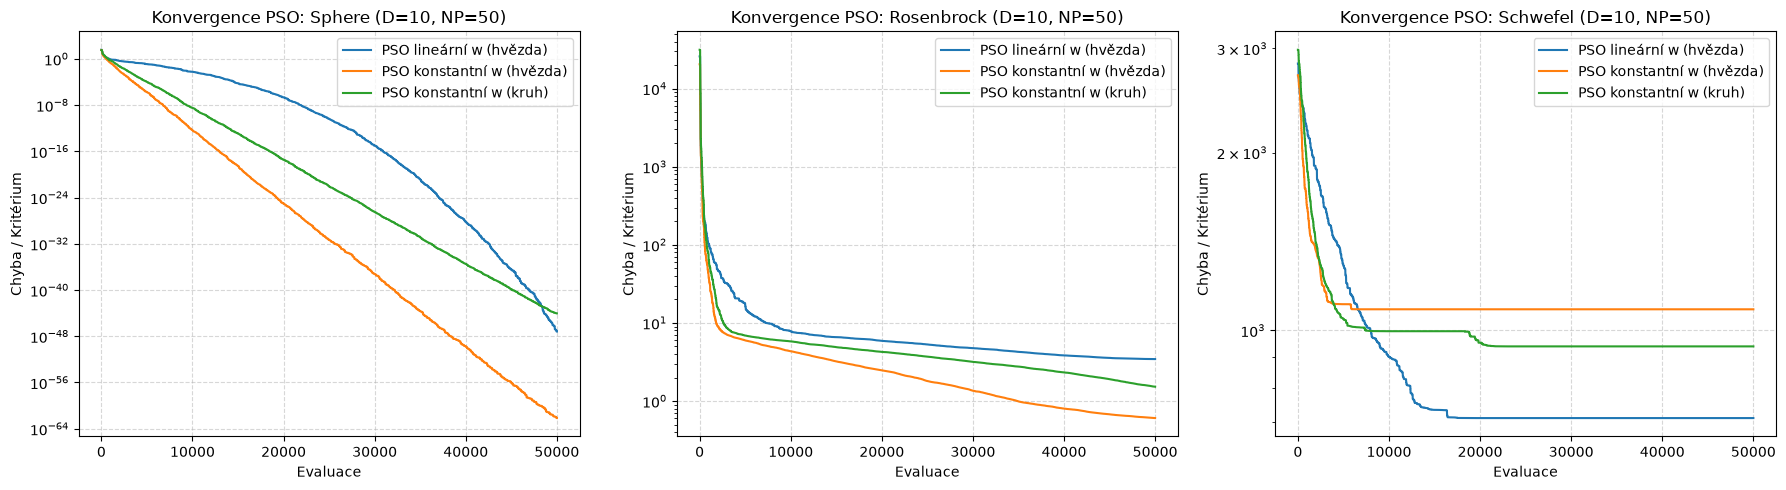

,Funkce,Varianta,Nejlepší,Nejhorší,Průměr,Medián,Směr. odchylka
0,Sphere,PSO lineární w (hvězda),9.659802e-52,4.943520e-47,6.484350e-48,7.826980e-49,1.460247e-47
1,Sphere,PSO konstantní w (hvězda),7.886010e-66,4.231068e-62,6.959902e-63,1.148237e-64,1.389232e-62
2,Sphere,PSO konstantní w (kruh),6.653582e-47,5.950854e-44,8.993144e-45,1.710520e-45,1.727635e-44
3,Rosenbrock,PSO lineární w (hvězda),9.385194e-01,4.419434e+00,3.442993e+00,3.662270e+00,9.008162e-01
4,Rosenbrock,PSO konstantní w (hvězda),3.218223e-02,4.196497e+00,6.049048e-01,1.969723e-01,1.204200e+00
5,Rosenbrock,PSO konstantní w (kruh),7.462600e-01,1.915520e+00,1.525251e+00,1.532927e+00,3.011950e-01
6,Schwefel,PSO lineární w (hvězda),3.553151e+02,1.046208e+03,7.106318e+02,7.501123e+02,2.192809e+02
7,Schwefel,PSO konstantní w (hvězda),7.502151e+02,1.362082e+03,1.085722e+03,1.095614e+03,1.802611e+02
8,Schwefel,PSO konstantní w (kruh),5.724548e+02,1.401542e+03,9.396340e+02,8.981657e+02,2.196846e+02


In [4]:
dim = 10
max_evals = 50000
num_runs = 10
pop_size = 50
problems = {
    "Sphere": (sphere, -5.12, 5.12),
    "Rosenbrock": (rosenbrock, -5.0, 5.0),
    "Schwefel": (schwefel, -500.0, 500.0)
}
variants = {
    "PSO lineární w (hvězda)": {"topology": "star", "w_start": 0.8, "w_end": 0.3, "c1": 2.0, "c2": 2.0},
    "PSO konstantní w (hvězda)": {"topology": "star", "w_start": 0.7, "w_end": 0.7, "c1": 1.49618, "c2": 1.49618},
    "PSO konstantní w (kruh)": {"topology": "ring", "w_start": 0.7, "w_end": 0.7, "c1": 1.49618, "c2": 1.49618, "radius": 3}
}

fig, axes = plt.subplots(1, len(problems), figsize=(18, 5))
stats_records = []

for p_idx, (p_name, (p_fn, lb, ub)) in enumerate(problems.items()):
    ax = axes[p_idx]

    for v_name, params in variants.items():
        runs_convergence = []
        runs_scores = []
        for _ in range(num_runs):
            conv, best_val = run_pso(
                cost_fn=p_fn, dim=dim, lb=lb, ub=ub, max_evals=max_evals, pop_size=pop_size, **params
            )
            runs_convergence.append(conv)
            runs_scores.append(best_val)

        ax.plot(np.mean(runs_convergence, axis=0), label=v_name)

        stats_records.append({
            "Funkce": p_name,
            "Varianta": v_name,
            "Nejlepší": np.min(runs_scores),
            "Nejhorší": np.max(runs_scores),
            "Průměr": np.mean(runs_scores),
            "Medián": np.median(runs_scores),
            "Směr. odchylka": np.std(runs_scores)
        })

    ax.set_title(f"Konvergence PSO: {p_name} (D={dim}, NP={pop_size})")
    ax.set_xlabel("Evaluace")
    ax.set_ylabel("Chyba / Kritérium")
    ax.set_yscale("log")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend()

plt.tight_layout()
plt.show()

df_stats = pd.DataFrame(stats_records)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
display(df_stats)


## Závěr

V rámci úlohy jsem implementoval algoritmus PSO ve třech variantách: s lineárně klesající setrvačností a globální topologií (hvězda), s konstantní setrvačností a globální topologií a s konstantní setrvačností a kruhovou topologií. Ve všech variantách je rychlost omezena na $v_{max} = 0{,}2 \cdot Range$, počáteční rychlost je nulová a částice smí opustit prohledávanou oblast, kde se ale neohodnocuje a její pBest se nemění. Testování proběhlo na funkcích Sphere, Rosenbrock a Schwefel (D=10) při limitu $MAXFES = 50\,000$ evaluací, velikosti populace $NP = 50$ a 10 nezávislých bězích.

Z naměřených konvergenčních křivek a statistických ukazatelů lze vyvodit:

* **Ukázka jednoho kroku:**
  * Nová rychlost vzniká součtem setrvačné, kognitivní a sociální složky, přičemž každý parametr dostane vlastní náhodné číslo ($NP = 7$, $w = 0{,}7$, $c_1 = c_2 = 1{,}49618$).
  * Omezení $v_{max} = 0{,}2 \cdot Range$ v ukázce zasáhlo 4 ze 6 parametrů, takže se nová pozice posunula jen o povolenou délku kroku. Nová pozice je výrazně lepší než původní ($33{,}9$ proti $87{,}4$).

* **Lineární setrvačnost, hvězda ($w = 0{,}8 \to 0{,}3$, $c_1 = c_2 = 2$):**
  * Na Sphere konverguje nejpomaleji. Vysoké $c_1 = c_2 = 2$ a velká počáteční setrvačnost udržují roj dlouho rozptýlený a přesnost se zlepšuje až s klesajícím $w$ (průměr $6{,}5 \cdot 10^{-48}$). Na Rosenbrocku je nejhorší (průměr $3{,}44$ proti $0{,}60$ u konstantního $w$).
  * Na Schwefelu je naopak nejlepší (průměr $711$, nejlepší běh $355$), protože roj prohledává široce a zlepšuje se ještě zhruba do 17 000 evaluací, tedy déle než ostatní varianty. Optimum ($0$) nenašel ani on.

* **Konstantní setrvačnost, hvězda ($w = 0{,}7$, $c_1 = c_2 = 1{,}49618$):**
  * Nejrychleji a nejpřesněji konverguje na Sphere ($6{,}96 \cdot 10^{-63}$) a nejlepšího průměru dosáhla i na Rosenbrocku ($0{,}60$ při mediánu $0{,}20$). Průměr je však zhoršený jedním během, který uvázl (nejhorší $4{,}2$, směrodatná odchylka $1{,}2$).
  * Na Schwefelu je nejhorší (průměr $1\,086$), protože všechny částice rychle konvergují k jednomu gBestu a křivka se zastaví už zhruba po 6 000 evaluacích.

* **Konstantní setrvačnost, kruh ($w = 0{,}7$, $c_1 = c_2 = 1{,}49618$, sousedství 3):**
  * Informace se šíří pomaleji, a proto je konvergence na Sphere pomalejší než u hvězdy (průměr $9{,}0 \cdot 10^{-45}$ proti $7{,}0 \cdot 10^{-63}$). Na Rosenbrocku vychází průměr $1{,}53$ s nejmenším rozptylem výsledků ze všech variant (směrodatná odchylka $0{,}30$).
  * Na Schwefelu dosáhl průměru $940$, tedy lepšího než hvězda se stejnými parametry, ale horšího než varianta s lineárním $w$. Pomalejší šíření gBestu uvázlému roji pomáhá jen částečně.

* **Celkové srovnání:**
  * Žádná varianta nevyhrála na všech funkcích. Na Sphere a Rosenbrocku je nejlepší konstantní $w$ s hvězdou, na Schwefelu lineárně klesající $w$.
  * Hvězda konverguje nejrychleji, ale snadno uvázne v lokálním minimu. Kruh je pomalejší, ale stabilnější. Lineárně klesající setrvačnost zlepšuje průzkum na začátku běhu, ale na jednoduchých funkcích stojí rychlost konvergence.
  * Na Schwefelu žádná varianta při daném rozpočtu nenašla globální optimum, všechny jsou i v nejlepším běhu stále daleko od nuly.
  